# Conditional U-Net diffusion training
Predict added Gaussian noise using a U-Net conditioned on sinusoidal timestep embeddings and learned digit embeddings in every residual block. Downsampling captures context; concatenated down/up skip connections preserve stroke detail. Explicit interpolation to skip sizes preserves the original image shape. The time embedding dimension is configurable rather than hard-coded.

In [1]:
import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
STARTER = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model/cgan.py').is_file())
sys.path.insert(0, str(STARTER))
from model.diffusion import ConditionalUNet
from training.train_diffusion import DiffusionSchedule, train_diffusion, sample_images
from data_utils.dataloader import get_mnist_loaders
from utils.runtime import setup
from utils.generation import load_generator
from utils.checkpoint import CHECKPOINT_DIR, OUTPUT_DIR
from utils.visualize import show_batch
device = setup(42)
print('Device:', device)

Device: cuda


In [2]:
num_classes, timesteps, batch_size = 10, 1000, 128
epochs, learning_rate = 40, 2e-4
model_config = dict(num_classes=10, img_channels=1, base_channels=32, time_dim=128)
schedules = ('linear', 'cosine')  # Train both for the schedule comparison in notebook 03.
train_loader, _ = get_mnist_loaders(batch_size, pin_memory=device.type == 'cuda')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Forward diffusion (q sampling)
Let `alpha_t = 1-beta_t` and `alpha_bar_t = product(alpha_0...alpha_t)`. Draw `epsilon ~ N(0,I)` and use `x_t = sqrt(alpha_bar_t)*x_0 + sqrt(1-alpha_bar_t)*epsilon`. Timesteps are indexed `0...T-1`; even index 0 has a small amount of noise. The training target is the **actual sampled epsilon**, not the clean image.

The linear schedule uses the standard endpoints `1e-4...0.02` at T=1000 (scaled for other T). Cosine uses cumulative squared cosine signal power with offset 0.008 and clipped betas. The following plot checks that both approach a nearly pure-noise endpoint.

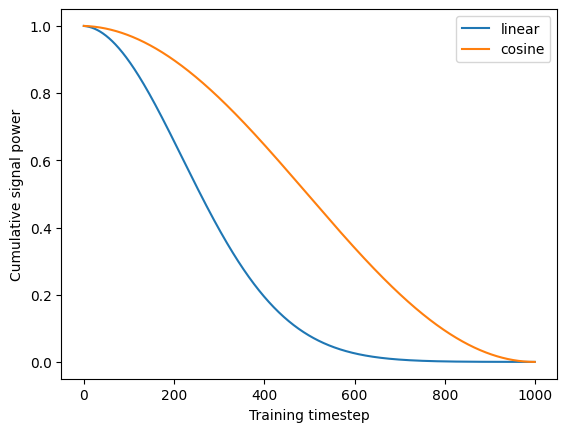

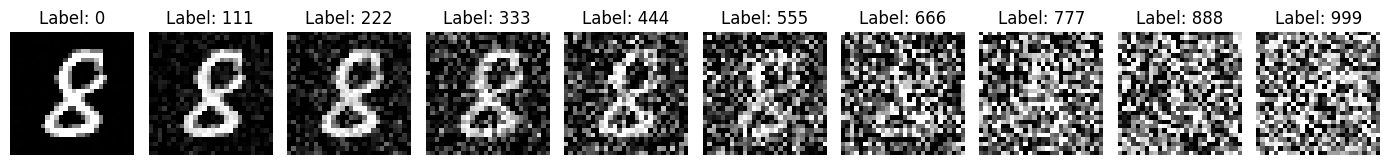

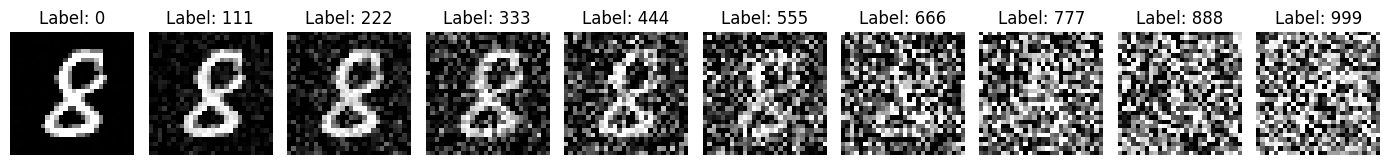

In [3]:
for schedule in schedules:
    noise_schedule = DiffusionSchedule(timesteps, schedule)
    plt.plot(noise_schedule.alpha_bar, label=schedule)
plt.xlabel('Training timestep'); plt.ylabel('Cumulative signal power'); plt.legend(); plt.show()
clean, labels = next(iter(train_loader))
steps = torch.linspace(0, timesteps - 1, 10).long()
clean = clean[:1].repeat(10, 1, 1, 1)
noise = torch.randn_like(clean)
noisy = DiffusionSchedule(timesteps, 'cosine').q_sample(clean, steps, noise)
show_batch(noisy, steps, n=10, columns=10)

## Noise-prediction MSE and EMA
For each batch sample uniform random t, construct x_t, compute `MSE(UNet(x_t,t,y), epsilon)`, backpropagate, clip gradients and step AdamW. An exponential moving average (EMA) of weights stabilizes sampling. Epoch-average losses and schedule/architecture metadata are saved so later notebooks cannot accidentally switch schedules.

Both schedules start from the same seed, model architecture, dataset order, epochs and optimization budget. Sampling later uses the same DDIM call budget for a fair schedule comparison. A single seed is illustrative rather than statistically conclusive. Two runs roughly double training cost.

diffusion_linear: epoch 1/40, MSE=0.08701, updates=469, AMP skips=0
diffusion_linear: epoch 2/40, MSE=0.03603, updates=469, AMP skips=0
diffusion_linear: epoch 3/40, MSE=0.03061, updates=469, AMP skips=0
diffusion_linear: epoch 4/40, MSE=0.02834, updates=469, AMP skips=0
diffusion_linear: epoch 5/40, MSE=0.02710, updates=469, AMP skips=0
diffusion_linear: epoch 6/40, MSE=0.02628, updates=469, AMP skips=0
diffusion_linear: epoch 7/40, MSE=0.02574, updates=469, AMP skips=0
diffusion_linear: epoch 8/40, MSE=0.02531, updates=469, AMP skips=0
diffusion_linear: epoch 9/40, MSE=0.02517, updates=469, AMP skips=0
diffusion_linear: epoch 10/40, MSE=0.02441, updates=469, AMP skips=0
diffusion_linear: epoch 11/40, MSE=0.02443, updates=469, AMP skips=0
diffusion_linear: epoch 12/40, MSE=0.02412, updates=469, AMP skips=0
diffusion_linear: epoch 13/40, MSE=0.02383, updates=469, AMP skips=0
diffusion_linear: epoch 14/40, MSE=0.02356, updates=469, AMP skips=0
diffusion_linear: epoch 15/40, MSE=0.02358,

diffusion_linear epoch 22 batch 213: AMP gradient overflow; skipped optimizer and EMA updates, loss scale 2.09715e+06 -> 1.04858e+06.


diffusion_linear: epoch 22/40, MSE=0.02302, updates=468, AMP skips=1
diffusion_linear: epoch 23/40, MSE=0.02274, updates=469, AMP skips=0
diffusion_linear: epoch 24/40, MSE=0.02275, updates=469, AMP skips=0
diffusion_linear: epoch 25/40, MSE=0.02265, updates=469, AMP skips=0
diffusion_linear: epoch 26/40, MSE=0.02222, updates=469, AMP skips=0


diffusion_linear epoch 27 batch 175: AMP gradient overflow; skipped optimizer and EMA updates, loss scale 2.09715e+06 -> 1.04858e+06.


diffusion_linear: epoch 27/40, MSE=0.02228, updates=468, AMP skips=1
diffusion_linear: epoch 28/40, MSE=0.02247, updates=469, AMP skips=0
diffusion_linear: epoch 29/40, MSE=0.02266, updates=469, AMP skips=0
diffusion_linear: epoch 30/40, MSE=0.02207, updates=469, AMP skips=0
diffusion_linear: epoch 31/40, MSE=0.02222, updates=469, AMP skips=0


diffusion_linear epoch 32 batch 190: AMP gradient overflow; skipped optimizer and EMA updates, loss scale 2.09715e+06 -> 1.04858e+06.


... (5 outputs left out)

diffusion_cosine epoch 25 batch 290: AMP gradient overflow; skipped optimizer and EMA updates, loss scale 1.04858e+06 -> 524288.


diffusion_cosine: epoch 25/40, MSE=0.03937, updates=468, AMP skips=1
diffusion_cosine: epoch 26/40, MSE=0.03886, updates=469, AMP skips=0
diffusion_cosine: epoch 27/40, MSE=0.03894, updates=469, AMP skips=0
diffusion_cosine: epoch 28/40, MSE=0.03910, updates=469, AMP skips=0
diffusion_cosine: epoch 29/40, MSE=0.03922, updates=469, AMP skips=0
diffusion_cosine: epoch 30/40, MSE=0.03846, updates=469, AMP skips=0
diffusion_cosine: epoch 31/40, MSE=0.03872, updates=469, AMP skips=0
diffusion_cosine: epoch 32/40, MSE=0.03862, updates=469, AMP skips=0


diffusion_cosine epoch 33 batch 141: AMP gradient overflow; skipped optimizer and EMA updates, loss scale 1.04858e+06 -> 524288.


diffusion_cosine: epoch 33/40, MSE=0.03859, updates=468, AMP skips=1
diffusion_cosine: epoch 34/40, MSE=0.03844, updates=469, AMP skips=0
diffusion_cosine: epoch 35/40, MSE=0.03830, updates=469, AMP skips=0
diffusion_cosine: epoch 36/40, MSE=0.03818, updates=469, AMP skips=0
diffusion_cosine: epoch 37/40, MSE=0.03822, updates=469, AMP skips=0
diffusion_cosine: epoch 38/40, MSE=0.03834, updates=469, AMP skips=0
diffusion_cosine: epoch 39/40, MSE=0.03814, updates=469, AMP skips=0
diffusion_cosine: epoch 40/40, MSE=0.03828, updates=469, AMP skips=0


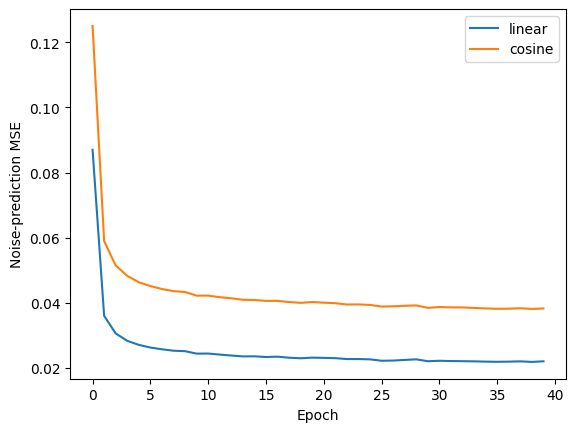

In [4]:
histories = {}
for schedule in schedules:
    setup(42)
    train_loader, _ = get_mnist_loaders(batch_size, pin_memory=device.type == 'cuda', seed=42)
    model = ConditionalUNet(**model_config).to(device)
    histories[schedule] = train_diffusion(
        model, train_loader, device, num_classes, timesteps=timesteps,
        epochs=epochs, lr=learning_rate, schedule=schedule,
        checkpoint_dir=CHECKPOINT_DIR, name=f'diffusion_{schedule}',
    )
    del model
for name, history in histories.items():
    plt.plot([row['mse'] for row in history], label=name)
plt.xlabel('Epoch'); plt.ylabel('Noise-prediction MSE'); plt.legend(); plt.show()

## Reverse sampling from T to zero
`sample_images` starts at Gaussian noise, predicts epsilon and clipped x_0, then samples the DDPM posterior at every training timestep down through zero. It uses posterior variance `beta_t*(1-alpha_bar_previous)/(1-alpha_bar_t)` and **adds no noise at the last step**.

Full DDPM below demonstrates the complete reverse loop. Optional deterministic DDIM sampling follows a subset of the original training indices for fewer network calls. Reducing sampling steps must **not** rebuild the beta schedule or change the trained time horizon. The evaluator measures FID versus this DDIM call budget.

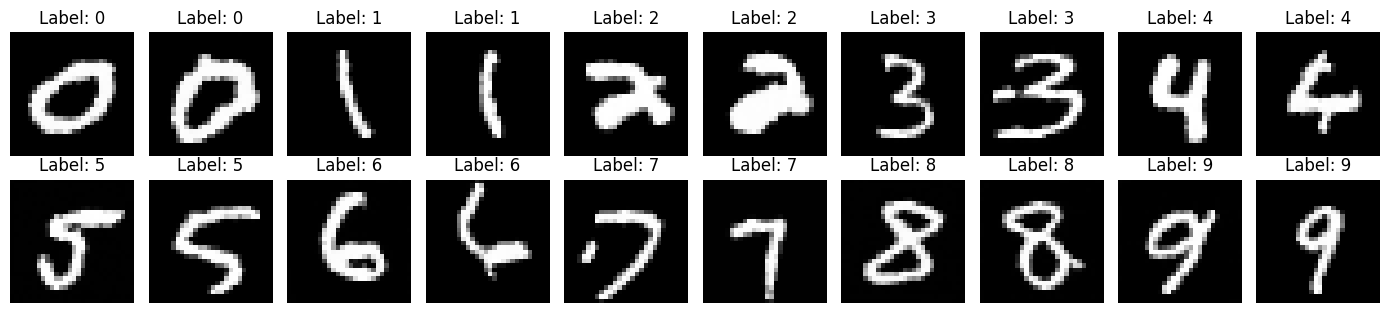

In [5]:
model = load_generator(CHECKPOINT_DIR / 'diffusion_cosine_epochfinal.pt', 'diffusion', device)
labels = torch.arange(10, device=device).repeat_interleave(2)
images, labels = sample_images(
    model, device, num_samples=20, class_labels=labels, sampler='ddpm', seed=100,
)
figure = show_batch(images.cpu(), labels.cpu(), n=20, columns=10)
figure.savefig(OUTPUT_DIR / 'diffusion_ddpm.png', dpi=150)

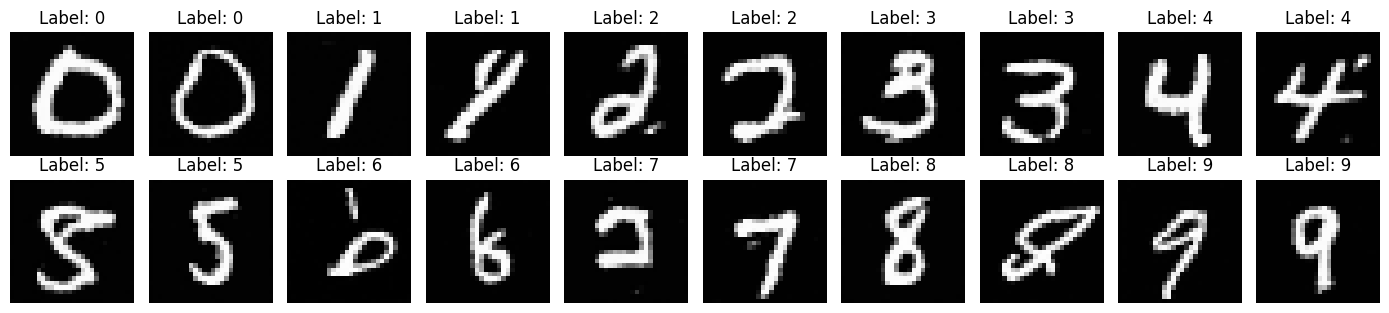

In [6]:
images, labels = sample_images(
    model, device, num_samples=20, class_labels=labels,
    sampler='ddim', sampling_steps=50, seed=100,
)
figure = show_batch(images.cpu(), labels.cpu(), n=20, columns=10)
figure.savefig(OUTPUT_DIR / 'diffusion_ddim.png', dpi=150)